In [1]:
!pip install transformers
!pip install pillow
!pip install torch
!pip install torchvision
!pip install torchaudio

In [19]:
from transformers import BlipProcessor , BlipForQuestionAnswering
from PIL import Image

In [20]:
processor = BlipProcessor.from_pretrained('Salesforce/blip-vqa-base')
model = BlipForQuestionAnswering.from_pretrained('Salesforce/blip-vqa-base')

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.54GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/788 [00:00<?, ?it/s]

In [21]:
image = Image.open('assets/animals.webp')

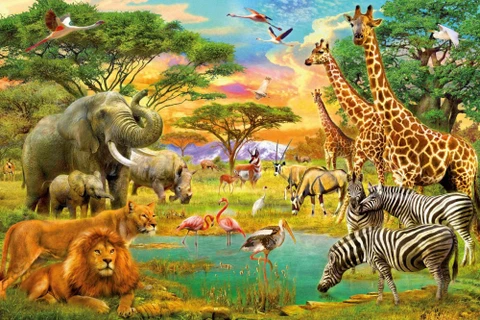

In [22]:
image

In [23]:
question = 'what animals are shown in image ? '

In [24]:
inputs = processor(image ,question , return_tensors = 'pt')

In [25]:
output = model.generate(**inputs)

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1954: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [26]:
answer = processor.decode(output[0] , skip_special_tokens = True)

In [27]:
answer

'zebras giraffes and elephants'

In [37]:
def img_question(path , question):
  image = Image.open(path)
  input = processor(image , question , return_tensors = 'pt')
  output = model.generate(**input)
  answer = processor.decode(output[0] , skip_spicial_token = True)
  return answer

In [38]:
print(img_question('assets/animals.webp' ,'give me count of girrafe ?'))

2 [SEP]


/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1954: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [39]:
img_question('assets/animals.webp' ,'give me count of Human ?')

'no [SEP]'

In [41]:
img_question('assets/forest.avif' ,'how many waterfall are there in image ?')

'2 [SEP]'